Анализ активности клиентов и выручки (SQL + Python)

Бизнес-смысл: Мы работаем в отделе аналитики. У нас есть база данных (customers, orders, employees). Руководство просит выгрузить данные о продажах, почистить их, найти аномалии и построить красивый график активности по месяцам.

Шаг 1. Подготовка исходных таблиц

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#Читаем csv файлы, созданные в pgadmin
orders=pd.read_csv('orders.csv')
customers=pd.read_csv('customers.csv')
employees=pd.read_csv('employees.csv')

print("данные загружены")
print("заказы: ", orders.shape)
print("клиенты: ", customers.shape)
print("сотрудники: ", employees.shape)   

данные загружены
заказы:  (12, 5)
клиенты:  (7, 3)
сотрудники:  (5, 5)


Шаг 2. Аналитика и объединение таблиц

In [9]:
#1 объединение заказов с клиентами
ord_cus=pd.merge(
    orders,
    customers,
    left_on='customer_id',
    right_on='id',
    how='left'
)
#2 объединение с сотрудниками
df_final=pd.merge(
    ord_cus,
    employees,
    left_on='employee_id',
    right_on='id',
    how='left',
    suffixes=('_client','_emp') #добавили суффиксы чтоб не путать одинаковые названия столбцов
)
#3 смотрим что получилось
print("\n--- Объединенная таблица (первые 5 строк) ---")
print(df_final.head())

#4 считаем выручку по городам
print("\n--- Выручка по городам ---")
city_rev=df_final.groupby('city')['amount'].sum().sort_values(ascending=False)
print(city_rev)

#5 считаем выручку по менеджерам
print("\n--- Выручка по сотрудникам ---")
employee_rev=df_final.groupby(['employee_id','name_emp'])['amount'].sum().sort_values(ascending=False)
print(employee_rev)




--- Объединенная таблица (первые 5 строк) ---
   id_x  employee_id  customer_id  amount  order_date  id_y    name_client  \
0     1            1            1   15000  2024-01-15     1    ООО Ромашка   
1     2            1            3   22000  2024-02-03     3  ООО ТехноСофт   
2     3            1            1   18000  2024-03-10     1    ООО Ромашка   
3     4            2            2   45000  2024-01-20     2      ИП Иванов   
4     5            2            4   38000  2024-02-14     4   ЗАО Прогресс   

              city  id name_emp     position  salary  department_id  
0           Москва   1      Аня     аналитик   80000              1  
1           Москва   1      Аня     аналитик   80000              1  
2           Москва   1      Аня     аналитик   80000              1  
3  Санкт-Петербург   2    Борис  разработчик  120000              2  
4           Казань   2    Борис  разработчик  120000              2  

--- Выручка по городам ---
city
Москва             172500
Санкт

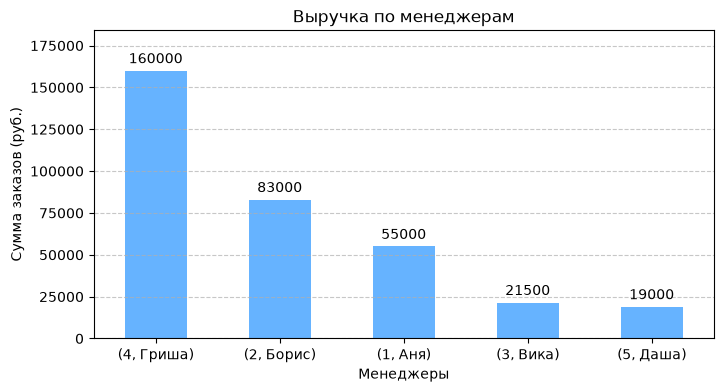

In [12]:
#6 строим столбчатую диаграмму
ax=employee_rev.plot(kind='bar',figsize=(8,4),color='#66b3ff')

#7 Добавляем подписи значений на стоблцы
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f',padding=3,fontsize=10)

#8 Оформление диаграммы
plt.title('Выручка по менеджерам')
plt.ylabel('Сумма заказов (руб.)')
plt.xlabel('Менеджеры')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, employee_rev.max() * 1.15) # <--- Вот тут точка!

plt.show()

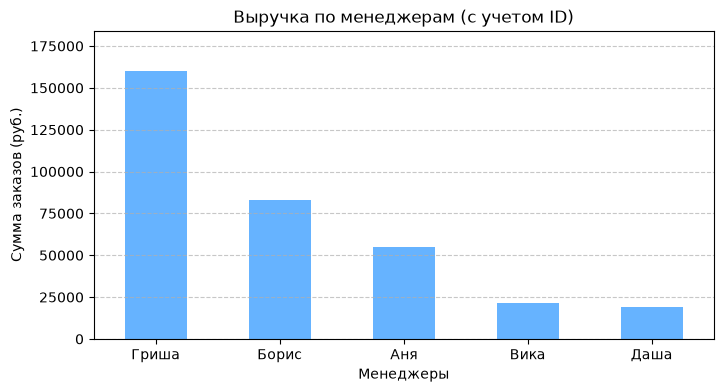

In [13]:
# 9. Сбрасываем индексы, чтобы получить обычную таблицу
employee_rev_flat = employee_rev.reset_index()

# 10. Сортируем по сумме
employee_rev_flat = employee_rev_flat.sort_values('amount', ascending=False)

# 11. Строим график по имени (но данные уже разделены по ID!)
ax = employee_rev_flat.plot(x='name_emp', y='amount', kind='bar', figsize=(8, 4), color='#66b3ff', legend=False)

# 12. Настройки оформления
plt.title('Выручка по менеджерам (с учетом ID)')
plt.ylabel('Сумма заказов (руб.)')
plt.xlabel('Менеджеры')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, employee_rev_flat['amount'].max() * 1.15)

plt.show()